In [3]:
import sys
sys.path.append("external/ECGFounder")

In [4]:
import torch
from net1d import Net1D

In [5]:
model = Net1D(
    in_channels=12,
    base_filters=64,
    ratio=1,
    filter_list=[64, 160, 160, 400, 400, 1024, 1024],
    m_blocks_list=[2, 2, 2, 3, 3, 4, 4],
    kernel_size=16,
    stride=2,
    groups_width=16,
    verbose=False,
    use_bn=False,
    use_do=False,
    n_classes=150,
    return_features=True,
)

In [6]:
checkpoint = torch.load("checkpoint/12_lead_ECGFounder.pth", map_location="cpu", weights_only=False)
log = model.load_state_dict(checkpoint["state_dict"], strict=False)

print("Mangler:", log.missing_keys)
print("Ukjente:", log.unexpected_keys)

Mangler: []
Ukjente: []


In [7]:
import wfdb

signal, meta = wfdb.rdsamp("00001_hr", pn_dir="ptb-xl/1.0.3/records500/00000")

print(signal.shape)
print(meta["fs"])
print(meta["sig_name"])

(5000, 12)
500
['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


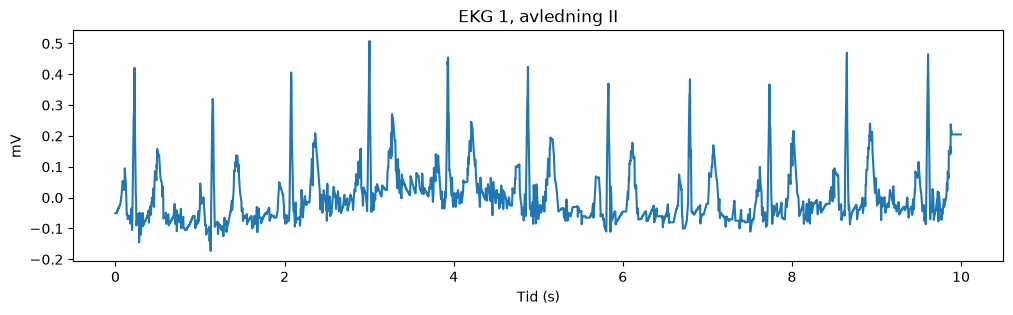

In [8]:
import matplotlib.pyplot as plt
import numpy as np

tid = np.arange(signal.shape[0]) / meta["fs"]

plt.figure(figsize=(12, 3))
plt.plot(tid, signal[:, 1])
plt.xlabel("Tid (s)")
plt.ylabel("mV")
plt.title("EKG 1, avledning II")
plt.show()

In [9]:
x = signal.T
x = (x - x.mean()) / (x.std() + 1e-8)
x = torch.tensor(x, dtype=torch.float32).unsqueeze(0)

print(x.shape)


torch.Size([1, 12, 5000])


In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()

with torch.no_grad():
    logits, embedding = model(x.to(device))

print(logits.shape)
print(embedding.shape)

torch.Size([1, 150])
torch.Size([1, 1024])


In [11]:
diagnoser = [linje.strip() for linje in open("external/ECGFounder/tasks.txt")]
sannsynlighet = torch.sigmoid(logits[0])

topp5 = sannsynlighet.argsort(descending=True)[:5]
for i in topp5:
    print(f"{sannsynlighet[i]:.3f}  {diagnoser[i]}")

0.999  SINUS RHYTHM
0.999  NORMAL SINUS RHYTHM
0.990  NORMAL ECG
0.365  LOW VOLTAGE QRS
0.190  BORDERLINE ECG
